# 🛣️ Pavement Crack Detection: CNN vs Vision Transformer
Binary image classification (**Positive** = crack, **Negative** = no crack). Two models are trained from scratch, compared, and the better one is exported for the Streamlit app.

**Pipeline:** Setup → Data Loading → Preprocessing → EDA → Feature Engineering → CNN → ViT → Training → Evaluation → Export

> **Google Colab:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. The model zip downloads automatically at the end.

## 1. Setup
Imports, reproducibility, and one config dict for every hyperparameter.

In [1]:
import os, sys, json, time, shutil, datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

SEED = 42
keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")

CFG = {
    "dataset": "oluwaseunad/concrete-and-pavement-crack-images",
    "img_size": 224,
    "batch_size": 64,
    "epochs": int(os.environ.get("EPOCHS", 30)),   # early stopping usually ends sooner
    "lr": 1e-3,
    "weight_decay": 1e-4,
    # ViT
    "patch_size": 16,
    "proj_dim": 64,
    "num_heads": 4,
    "transformer_layers": 6,
    "mlp_ratio": 2,
}
CLASS_NAMES = ["Negative", "Positive"]
IMG = CFG["img_size"]
IN_COLAB = "google.colab" in sys.modules
OUT_DIR = Path("/content/export") if IN_COLAB else Path("export")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"TensorFlow {tf.__version__} | Keras {keras.__version__}")
print("GPU:", tf.config.list_physical_devices("GPU") or "none (CPU), in Colab switch to a T4 GPU runtime")

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data Loading
Download the dataset with `kagglehub`, then collect image paths + labels into a DataFrame (images are read lazily later, which saves RAM).

In [2]:
import kagglehub

path = os.environ.get("DATA_DIR") or kagglehub.dataset_download(CFG["dataset"])
print("Path to dataset files:", path)

def find_data_root(base):
    """Return the folder that contains the Negative/ and Positive/ class folders."""
    for d in [Path(base), *sorted(Path(base).rglob("*"))]:
        if d.is_dir() and all((d / c).is_dir() for c in CLASS_NAMES):
            return d
    raise FileNotFoundError(f"No {CLASS_NAMES} folders found under {base}")

DATA_DIR = find_data_root(path)
print("Class folders found in:", DATA_DIR)

Path to dataset files: /root/.cache/kagglehub/datasets/oluwaseunad/concrete-and-pavement-crack-images/versions/1
Class folders found in: /root/.cache/kagglehub/datasets/oluwaseunad/concrete-and-pavement-crack-images/versions/1


In [3]:
EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
rows = [(str(p), label)
        for label, cls in enumerate(CLASS_NAMES)
        for p in sorted((DATA_DIR / cls).iterdir())
        if p.suffix.lower() in EXTS]

df = pd.DataFrame(rows, columns=["path", "label"])
df["class"] = df["label"].map(dict(enumerate(CLASS_NAMES)))
print("Total images:", len(df))
df["class"].value_counts().to_frame("count")

Total images: 30000


,count
class,
Negative,15000
Positive,15000


## 3. Data Preprocessing
Remove corrupt/duplicate files → stratified **70 / 15 / 15** split → class weights → `tf.data` pipeline (resize, cache, prefetch).

In [4]:
def is_valid(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

before = len(df)
df = df.drop_duplicates("path")
df = df[df["path"].map(is_valid)].reset_index(drop=True)
print(f"Removed {before - len(df)} bad/duplicate files -> {len(df)} images left")

Removed 0 bad/duplicate files -> 30000 images left


In [5]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

split_summary = pd.DataFrame({name: d["class"].value_counts() for name, d in
                              [("train", train_df), ("val", val_df), ("test", test_df)]}).T
split_summary["total"] = split_summary.sum(axis=1)
split_summary

class,Negative,Positive,total
train,10500,10500,21000
val,2250,2250,4500
test,2250,2250,4500


In [6]:
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=train_df["label"].values)
CLASS_WEIGHTS = dict(enumerate(weights))
print("Class weights:", {CLASS_NAMES[k]: round(v, 3) for k, v in CLASS_WEIGHTS.items()})

Class weights: {'Negative': np.float64(1.0), 'Positive': np.float64(1.0)}


In [7]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    """Read -> decode -> resize -> uint8 (identical to the Streamlit app's preprocessing)."""
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG, IMG))
    return tf.saturate_cast(img, tf.uint8), label

def make_ds(frame, augment=None, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].values, frame["label"].values.astype("float32")))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()   # uint8 cache keeps memory low
    if shuffle:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(CFG["batch_size"]).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    if augment is not None:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

## 4. Exploratory Data Analysis
Class balance, sample images, image sizes and pixel intensity per class.

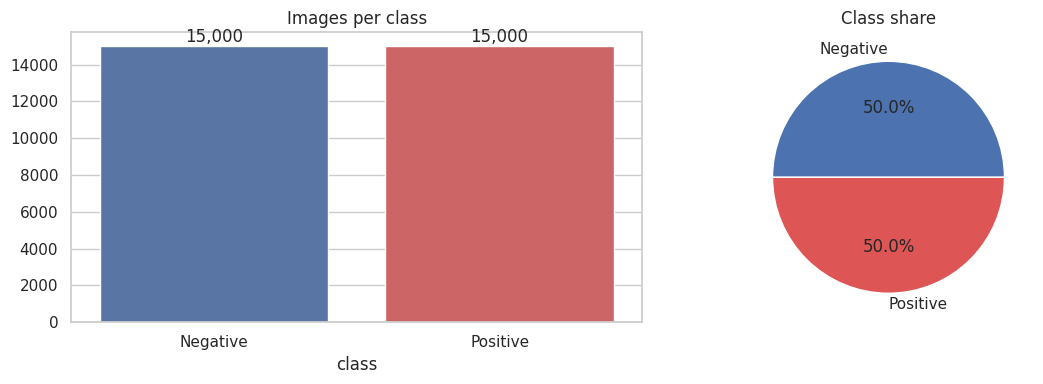

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = df["class"].value_counts()
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=["#4C72B0", "#DD5555"], legend=False, ax=axes[0])
axes[0].set_title("Images per class")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", colors=["#4C72B0", "#DD5555"])
axes[1].set_title("Class share")
plt.tight_layout(); plt.show()

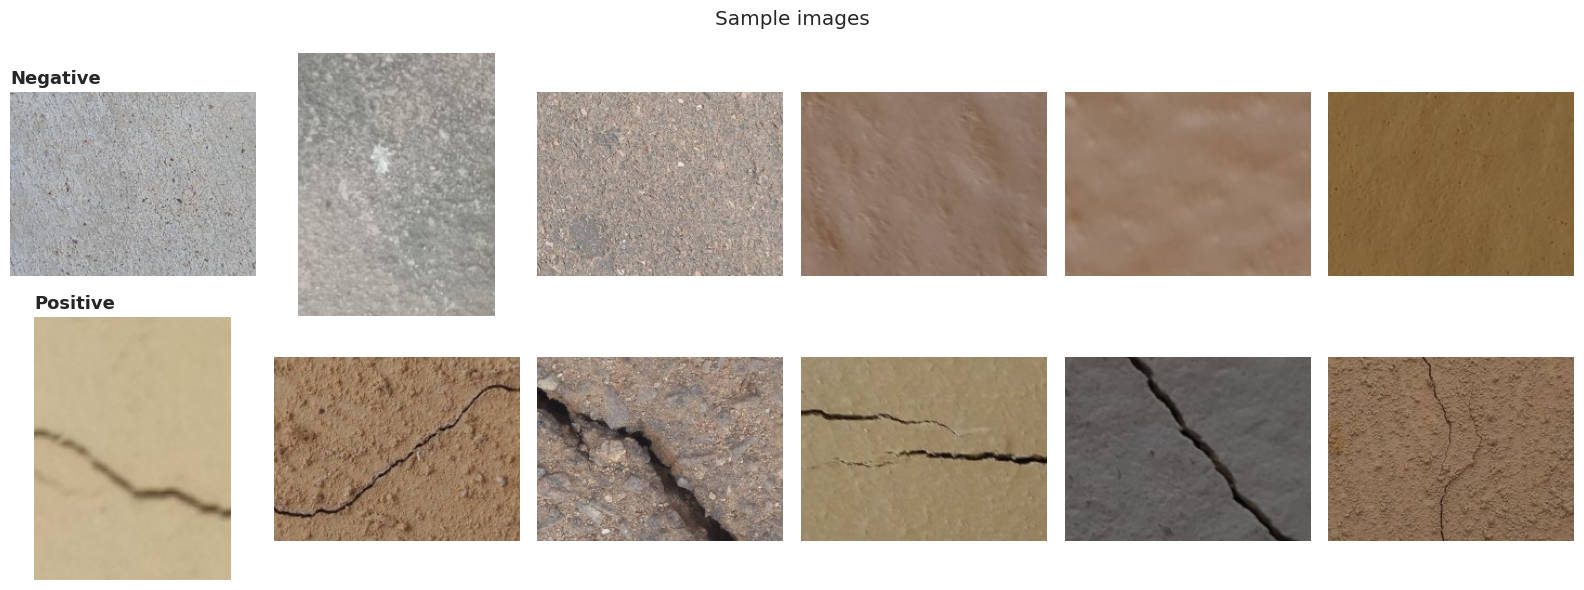

In [9]:
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for row, cls in enumerate(CLASS_NAMES):
    for ax, path in zip(axes[row], df[df["class"] == cls]["path"].sample(6, random_state=SEED)):
        ax.imshow(Image.open(path)); ax.axis("off")
    axes[row, 0].set_title(cls, loc="left", fontsize=13, fontweight="bold")
plt.suptitle("Sample images"); plt.tight_layout(); plt.show()

/tmp/ipykernel_2656/1448550876.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample = df.groupby("class", group_keys=False).apply(lambda d: d.sample(min(len(d), 300), random_state=SEED))


class             Negative  Positive
width      count     300.0     300.0
           mean      212.3     216.9
           std        24.9      23.1
           min       170.0      76.0
           25%       170.0     227.0
           50%       227.0     227.0
           75%       227.0     227.0
           max       227.0     227.0
height     count     300.0     300.0
           mean      184.8     179.1
           std        25.0      22.0
           min       170.0      73.0
           25%       170.0     170.0
           50%       170.0     170.0
           75%       227.0     170.0
           max       227.0     227.0
brightness count     300.0     300.0
           mean      132.4     131.3
           std        27.9      40.1
           min        72.4      47.9
           25%       114.8     102.7
           50%       133.1     131.1
           75%       149.2     152.5
           max       234.7     254.2
contrast   count     300.0     300.0
           mean       12.7      18.2
           std         7.1       8.1
           min         1.0       2.0
           25%         6.9      12.5
           50%        13.4      17.3
           75%        16.9      22.6
           max        55.2      48.7

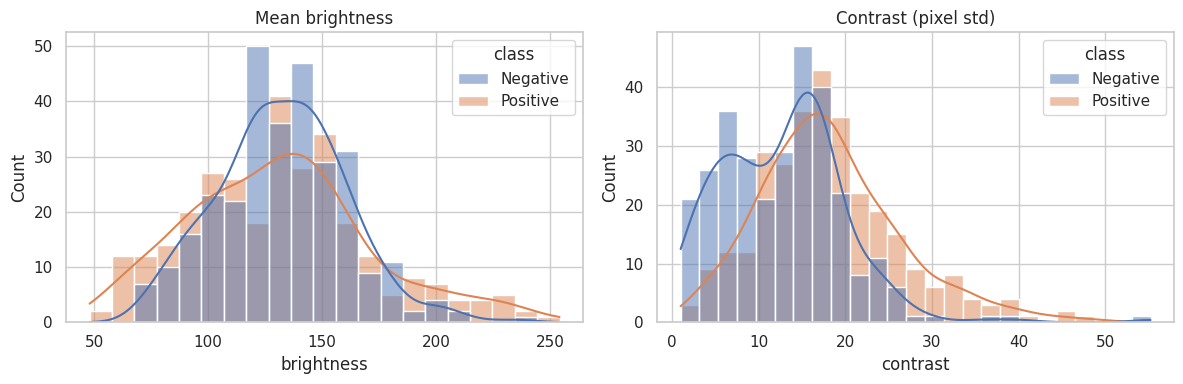

In [10]:
sample = df.groupby("class", group_keys=False).apply(lambda d: d.sample(min(len(d), 300), random_state=SEED))

def image_stats(path):
    arr = np.asarray(Image.open(path).convert("RGB"))
    gray = arr.mean(axis=2)
    return arr.shape[1], arr.shape[0], gray.mean(), gray.std()

sample[["width", "height", "brightness", "contrast"]] = [image_stats(p) for p in sample["path"]]
display(sample.groupby("class")[["width", "height", "brightness", "contrast"]].describe().T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(sample, x="brightness", hue="class", kde=True, ax=axes[0]).set_title("Mean brightness")
sns.histplot(sample, x="contrast", hue="class", kde=True, ax=axes[1]).set_title("Contrast (pixel std)")
plt.tight_layout(); plt.show()

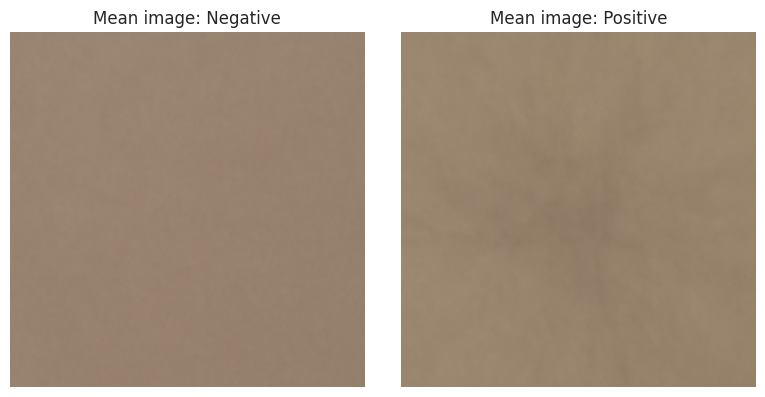

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, cls in zip(axes, CLASS_NAMES):
    paths = sample[sample["class"] == cls]["path"][:200]
    mean_img = np.mean([np.asarray(Image.open(p).convert("RGB").resize((IMG, IMG)), dtype=np.float32) for p in paths], axis=0)
    ax.imshow(mean_img.astype("uint8")); ax.set_title(f"Mean image: {cls}"); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Feature Engineering
**Edge maps** show the signal a model should learn (cracks = strong edges). **Augmentation** creates new training variations and only runs on the training set.

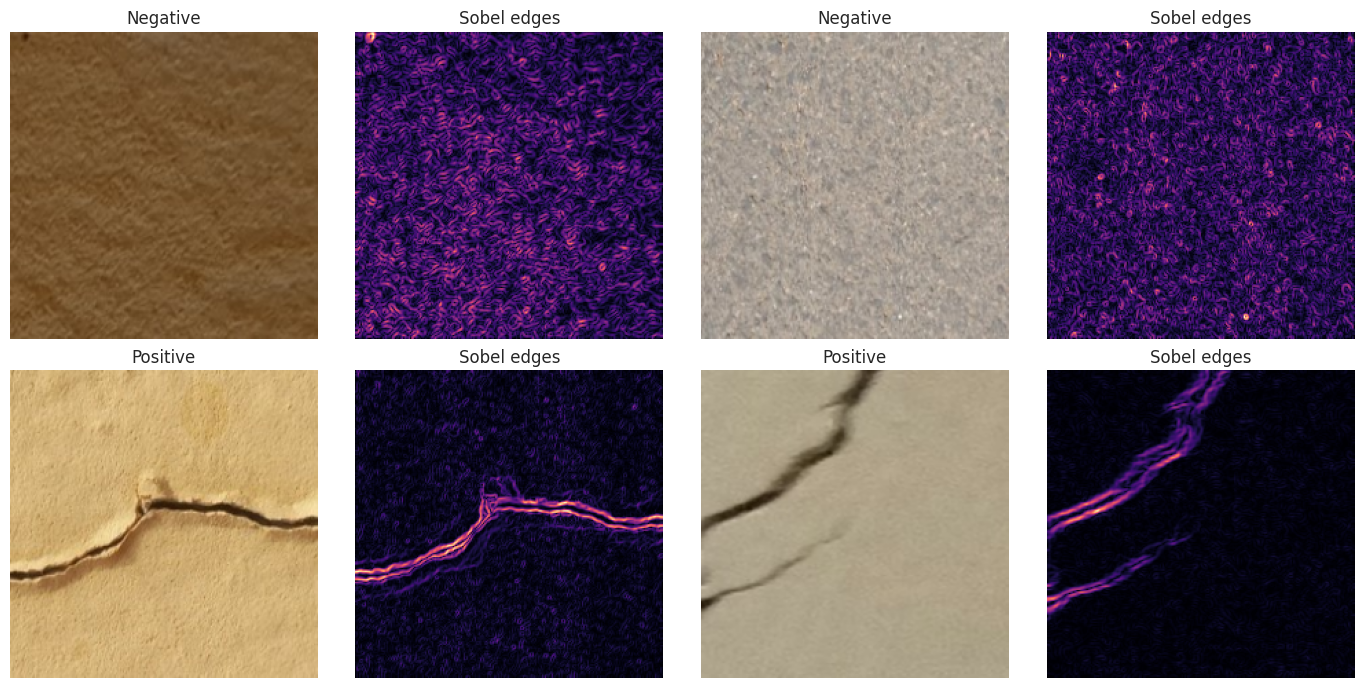

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, cls in enumerate(CLASS_NAMES):
    for col, path in enumerate(df[df["class"] == cls]["path"].sample(2, random_state=1)):
        img, _ = load_image(path, 0)
        gray = tf.image.rgb_to_grayscale(tf.cast(img, tf.float32))[None]
        edges = tf.norm(tf.image.sobel_edges(gray)[0, ..., 0, :], axis=-1)
        axes[row, col * 2].imshow(img); axes[row, col * 2].set_title(cls)
        axes[row, col * 2 + 1].imshow(edges, cmap="magma"); axes[row, col * 2 + 1].set_title("Sobel edges")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

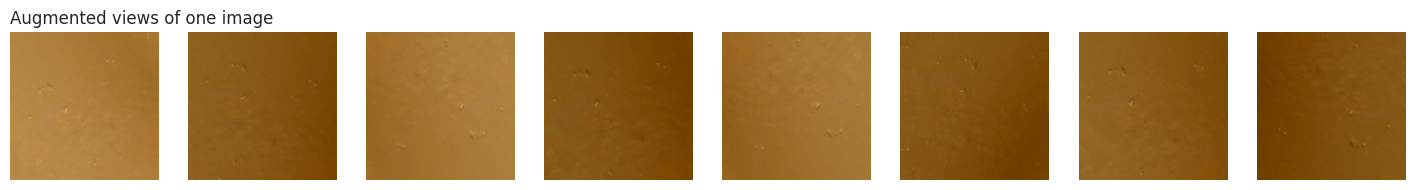

In [13]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.1, value_range=(0, 255)),
], name="augmentation")

img, _ = load_image(train_df["path"].iloc[0], 0)
batch = tf.repeat(tf.cast(img, tf.float32)[None], 8, axis=0)
aug = augment(batch, training=True)

fig, axes = plt.subplots(1, 8, figsize=(18, 3))
for i, ax in enumerate(axes):
    ax.imshow(tf.clip_by_value(aug[i], 0, 255).numpy().astype("uint8")); ax.axis("off")
axes[0].set_title("Augmented views of one image", loc="left")
plt.show()

In [14]:
train_ds = make_ds(train_df, augment=augment, shuffle=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

x, y = next(iter(train_ds))
print("Batch:", x.shape, x.dtype, "| labels:", y.shape, "| pixel range:", float(tf.reduce_min(x)), "-", float(tf.reduce_max(x)))

Batch: (64, 224, 224, 3) <dtype: 'float32'> | labels: (64,) | pixel range: 0.0 - 250.36346435546875


## 6. Model 1: CNN
Four Conv → BatchNorm → ReLU → MaxPool blocks, then GlobalAveragePooling, Dropout, and a sigmoid output. Rescaling is **inside** the model, so the model takes raw 0-255 images.

In [15]:
def build_cnn():
    inputs = keras.Input((IMG, IMG, 3), name="image")
    x = layers.Rescaling(1 / 255.0)(inputs)
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="crack_prob")(x)
    return keras.Model(inputs, outputs, name="CNN")

cnn = build_cnn()
cnn.summary()

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ crack_prob (Dense)              │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 390,113 (1.49 MB)

 Trainable params: 389,153 (1.48 MB)

 Non-trainable params: 960 (3.75 KB)

## 7. Model 2: Vision Transformer (ViT)
Split the image into 16×16 patches → linear patch embedding + learnable position embedding → Transformer encoder blocks → classifier.

224x224 image -> 196 patches of 16x16x3 = 768 values each


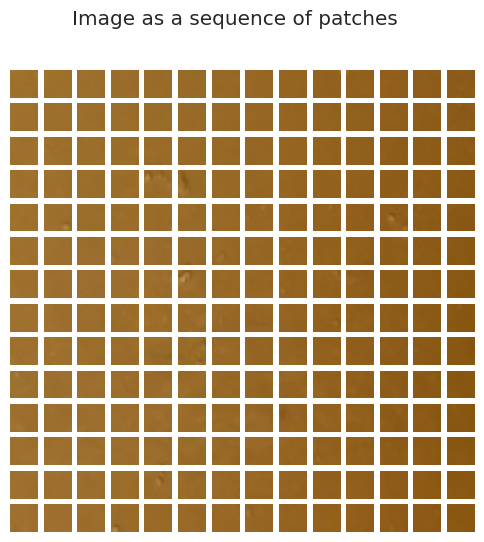

In [16]:
patch = CFG["patch_size"]
num_patches = (IMG // patch) ** 2

img, _ = load_image(train_df["path"].iloc[0], 0)
patches = tf.image.extract_patches(img[None], [1, patch, patch, 1], [1, patch, patch, 1], [1, 1, 1, 1], "VALID")
n = IMG // patch
print(f"{IMG}x{IMG} image -> {num_patches} patches of {patch}x{patch}x3 = {patch * patch * 3} values each")

fig, axes = plt.subplots(n, n, figsize=(6, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(tf.reshape(patches[0, i // n, i % n], (patch, patch, 3)).numpy()); ax.axis("off")
plt.suptitle("Image as a sequence of patches"); plt.show()

In [17]:
@keras.saving.register_keras_serializable(package="crack")
class PositionEmbedding(layers.Layer):
    """Adds a learnable position vector to each patch embedding."""
    def __init__(self, num_patches, dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches, self.dim = num_patches, dim

    def build(self, input_shape):
        self.pos = self.add_weight(name="pos", shape=(1, self.num_patches, self.dim),
                                   initializer=keras.initializers.RandomNormal(stddev=0.02))

    def call(self, x):
        return x + self.pos

    def get_config(self):
        return {**super().get_config(), "num_patches": self.num_patches, "dim": self.dim}


def transformer_block(x, dim, heads, mlp_ratio, dropout=0.1):
    h = layers.LayerNormalization(epsilon=1e-6)(x)
    h = layers.MultiHeadAttention(num_heads=heads, key_dim=dim // heads, dropout=dropout)(h, h)
    x = layers.Add()([x, h])
    h = layers.LayerNormalization(epsilon=1e-6)(x)
    h = layers.Dense(dim * mlp_ratio, activation="gelu")(h)
    h = layers.Dropout(dropout)(h)
    h = layers.Dense(dim)(h)
    return layers.Add()([x, h])


def build_vit():
    dim = CFG["proj_dim"]
    inputs = keras.Input((IMG, IMG, 3), name="image")
    x = layers.Rescaling(1 / 255.0)(inputs)
    x = layers.Conv2D(dim, patch, strides=patch, name="patch_embedding")(x)   # patchify + linear projection
    x = layers.Reshape((num_patches, dim))(x)
    x = PositionEmbedding(num_patches, dim)(x)
    for _ in range(CFG["transformer_layers"]):
        x = transformer_block(x, dim, CFG["num_heads"], CFG["mlp_ratio"])
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="crack_prob")(x)
    return keras.Model(inputs, outputs, name="ViT")

vit = build_vit()
vit.summary()

Model: "ViT"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 224, 224,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ image[0][0]       │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embedding     │ (None, 14, 14,    │     49,216 │ rescaling_1[0][0] │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 196, 64)   │          0 │ patch_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ position_embedding  │ (None, 196, 64)   │     12,544 │ reshape[0][0]     │
│ (PositionEmbedding) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 196, 64)   │        128 │ position_embeddi… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 196, 64)   │          0 │ position_embeddi… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 196, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 196, 128)  │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 196, 64)   │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 196, 64)   │          0 │ add[0][0],        │
│                     │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 196, 64)   │          0 │ add_1[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 196, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 262,785 (1.00 MB)

 Trainable params: 262,785 (1.00 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Training
**AdamW** + **class weights** + callbacks: **EarlyStopping** (restores the best weights), **ReduceLROnPlateau**, and **ModelCheckpoint**. The validation set is used for tuning; the test set stays unseen until evaluation.

In [18]:
def train(model):
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=CFG["lr"], weight_decay=CFG["weight_decay"]),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc"),
                 keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")],
    )
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6, verbose=1),
        keras.callbacks.ModelCheckpoint(str(OUT_DIR / f"{model.name}_best.keras"), monitor="val_loss", save_best_only=True),
    ]
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=5e,
                        class_weight=CLASS_WEIGHTS, callbacks=callbacks, verbose=1)
    print(f"{model.name} trained in {(time.time() - start) / 60:.1f} min")
    return history

histories = {}
histories["CNN"] = train(cnn)

Epoch 1/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 262s 730ms/step - accuracy: 0.8759 - auc: 0.9465 - loss: 0.3050 - precision: 0.8824 - recall: 0.8674 - val_accuracy: 0.5002 - val_auc: 0.8534 - val_loss: 1.1274 - val_precision: 1.0000 - val_recall: 4.4444e-04 - learning_rate: 0.0010
Epoch 2/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 238s 719ms/step - accuracy: 0.9337 - auc: 0.9817 - loss: 0.1761 - precision: 0.9427 - recall: 0.9235 - val_accuracy: 0.9431 - val_auc: 0.9881 - val_loss: 0.1492 - val_precision: 0.9721 - val_recall: 0.9124 - learning_rate: 0.0010
Epoch 3/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 227s 687ms/step - accuracy: 0.9531 - auc: 0.9896 - loss: 0.1304 - precision: 0.9610 - recall: 0.9447 - val_accuracy: 0.9111 - val_auc: 0.9842 - val_loss: 0.1922 - val_precision: 0.9884 - val_recall: 0.8320 - learning_rate: 0.0010
Epoch 4/5
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 677ms/step - accuracy: 0.9410 - auc: 0.9861 - loss: 0.1485 - precision: 0.9538 - recall: 0.9265
Epoch 4: ReduceLROnPlateau reducing learning rate t

In [26]:
histories["ViT"] = train(vit)

Epoch 1/5


KeyboardInterrupt: 

## 9. Evaluation
Learning curves, test metrics, confusion matrices, ROC curves, error analysis, and the final comparison.

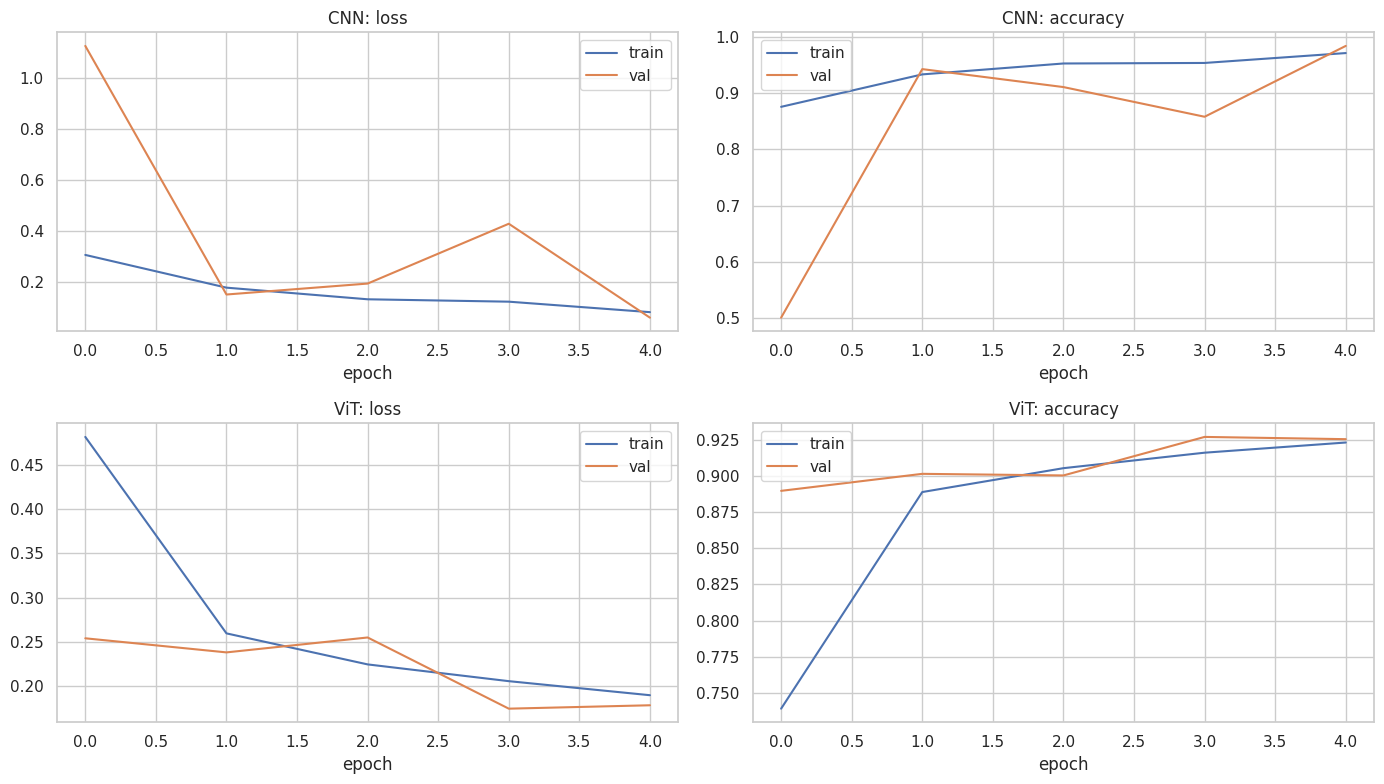

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, (name, h) in enumerate(histories.items()):
    for col, metric in enumerate(["loss", "accuracy"]):
        ax = axes[row, col]
        ax.plot(h.history[metric], label="train")
        ax.plot(h.history[f"val_{metric}"], label="val")
        ax.set_title(f"{name}: {metric}"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

In [21]:
y_test = test_df["label"].values
models = {"CNN": cnn, "ViT": vit}
probs, results = {}, []

for name, model in models.items():
    probs[name] = model.predict(test_ds, verbose=0).ravel()
    pred = (probs[name] >= 0.5).astype(int)
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, probs[name]),
        "params": model.count_params(),
        "epochs_run": len(histories[name].history["loss"]),
    })
    print(f"\n===== {name} =====")
    print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=4))

results_df = pd.DataFrame(results).set_index("model")
results_df.style.format({c: "{:.4f}" for c in ["accuracy", "precision", "recall", "f1", "roc_auc"]} | {"params": "{:,}"}) \
    .highlight_max(subset=["accuracy", "precision", "recall", "f1", "roc_auc"], color="#c6efce")


===== CNN =====
              precision    recall  f1-score   support

    Negative     0.9814    0.9840    0.9827      2250
    Positive     0.9840    0.9813    0.9826      2250

    accuracy                         0.9827      4500
   macro avg     0.9827    0.9827    0.9827      4500
weighted avg     0.9827    0.9827    0.9827      4500


===== ViT =====
              precision    recall  f1-score   support

    Negative     0.9132    0.9400    0.9264      2250
    Positive     0.9382    0.9107    0.9242      2250

    accuracy                         0.9253      4500
   macro avg     0.9257    0.9253    0.9253      4500
weighted avg     0.9257    0.9253    0.9253      4500



,accuracy,precision,recall,f1,roc_auc,params,epochs_run
model,,,,,,,
CNN,0.9827,0.9840,0.9813,0.9826,0.9977,"390,113",5
ViT,0.9253,0.9382,0.9107,0.9242,0.9833,"262,785",5


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes[:2], models):
    cm = confusion_matrix(y_test, (probs[name] >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{name} confusion matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    axes[2].plot(fpr, tpr, label=f"{name} (AUC = {results_df.loc[name, 'roc_auc']:.4f})")
axes[2].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[2].set_title("ROC curve"); axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate"); axes[2].legend()
plt.tight_layout(); plt.show()

🏆 Best model: CNN  (F1 = 0.9826)
Misclassified test images: 78 / 4500


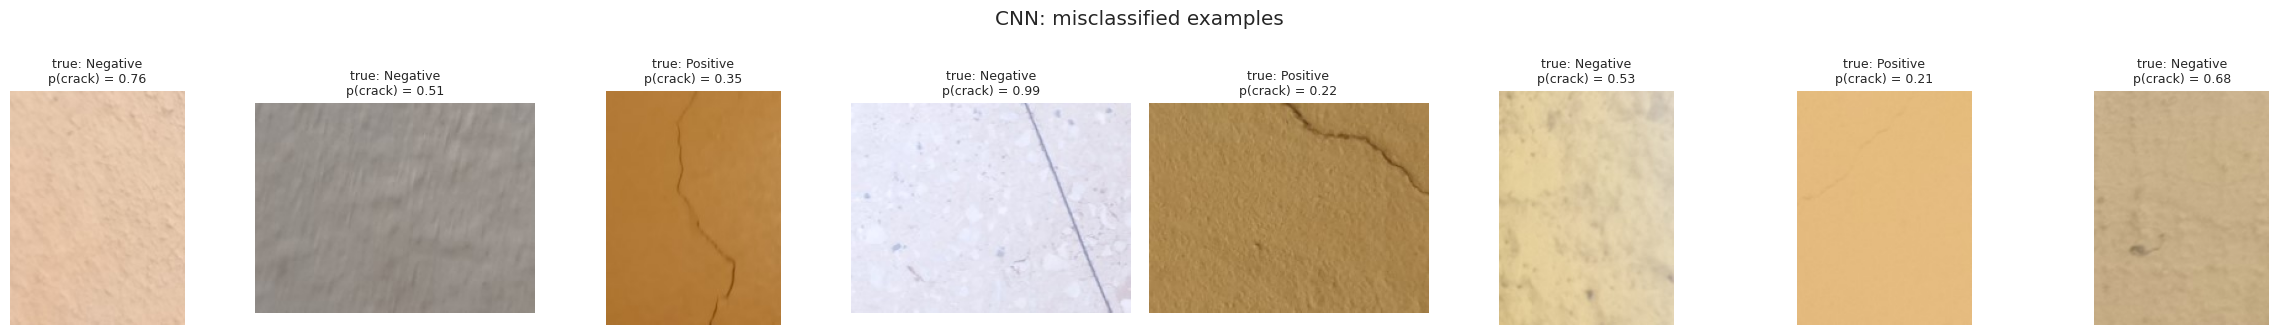

In [23]:
BEST = results_df.sort_values(["f1", "roc_auc"], ascending=False).index[0]
best_model = models[BEST]
print(f"🏆 Best model: {BEST}  (F1 = {results_df.loc[BEST, 'f1']:.4f})")

pred = (probs[BEST] >= 0.5).astype(int)
wrong = np.where(pred != y_test)[0]
print(f"Misclassified test images: {len(wrong)} / {len(y_test)}")

if len(wrong):
    show = wrong[:8]
    fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 3.4), squeeze=False)
    for ax, i in zip(axes[0], show):
        ax.imshow(Image.open(test_df["path"].iloc[i])); ax.axis("off")
        ax.set_title(f"true: {CLASS_NAMES[y_test[i]]}\np(crack) = {probs[BEST][i]:.2f}", fontsize=9)
    plt.suptitle(f"{BEST}: misclassified examples"); plt.tight_layout(); plt.show()

## 10. Export the Model
Save the best model + metadata, reload it to check it works, and zip it for download. Unzip into `crack_detection_app/model/`.

In [ ]:
MODEL_FILE = OUT_DIR / "crack_model.keras"
best_model.save(MODEL_FILE)

info = {
    "model_name": BEST,
    "class_names": CLASS_NAMES,
    "img_size": IMG,
    "threshold": 0.5,
    "input": "RGB uint8 0-255 resized to img_size (rescaling is inside the model)",
    "metrics": results_df.drop(columns=["params", "epochs_run"]).round(4).to_dict(orient="index"),
    "params": {k: int(v) for k, v in results_df["params"].items()},
    "confusion_matrix": confusion_matrix(y_test, pred).tolist(),
    "split_sizes": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
    "tensorflow_version": tf.__version__,
    "keras_version": keras.__version__,
    "trained_on": datetime.date.today().isoformat(),
}
(OUT_DIR / "model_info.json").write_text(json.dumps(info, indent=2))

# Sanity check: reload from disk and compare predictions
reloaded = keras.models.load_model(MODEL_FILE)
check = reloaded.predict(test_ds.take(1), verbose=0).ravel()
assert np.allclose(check, probs[BEST][:len(check)], atol=1e-4), "reloaded model gives different predictions!"
print("✅ Reloaded model matches. Size:", round(MODEL_FILE.stat().st_size / 1e6, 2), "MB")
print(json.dumps(info["metrics"][BEST], indent=2))

In [25]:
for f in OUT_DIR.glob("*_best.keras"):   # checkpoints are not needed in the download
    f.unlink()

zip_path = shutil.make_archive(str(OUT_DIR.parent / "crack_model_export"), "zip", OUT_DIR)
print("Exported files:", [p.name for p in OUT_DIR.iterdir()], "->", zip_path)

if IN_COLAB:
    from google.colab import files
    files.download(zip_path)   # browser download; also visible in the Files panel (left sidebar)

Exported files: ['model_info.json', 'crack_model.keras'] -> /content/crack_model_export.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>